# PTC Cell Detection from Kidney Tissue WSIs

## Project Overview
This project focuses on processing Whole Slide Images (WSIs) of kidney tissue to identify and analyze Peritubular Capillaries (PTCs). The tissue samples are immunohistochemically stained with:
- CD34 to visualize PTCs (red staining)
- CD45 to identify leukocytes

## Data Structure
The dataset consists of 10 folders, each containing:
- A `.ndpi` WSI file containing the kidney tissue scan
- A corresponding `.xml` file containing manual annotations of PTC cells

Path to the Raw Data = /orange/pinaki.sarder/durgasrit.dongla/PTC_IPTCR/Data/Raw_Data

### Step 1: Mask Generation
First, we create binary masks from the XML annotations:
- Process WSIs at level 2 magnification
- Parse XML files to extract PTC cell coordinates
- Create binary masks where:
  - PTC regions = 255 (white)
  - Background = 0 (black)
- Save masks as `.tiff` files to preserve binary values without compression

Path to the generated tiff masks: /orange/pinaki.sarder/durgasrit.dongla/PTC_IPTCR/Data/All_Masks

In [1]:
%matplotlib inline
import openslide
from openslide import open_slide  # Used to open the WSI images commonly used in digital pathology
from openslide.deepzoom import DeepZoomGenerator  # Handle and process large images by breaking them into manageable tiles at different zoom levels
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt
import os
import tifffile as tiff  # Enables loading and saving high-resolution .tiff images and metadata in a format optimized for these use cases
import xml.etree.ElementTree as ET
import random
from tifffile import imread
import math
from PIL import Image, ImageDraw

tree = None

Openslide library is basically like google maps. When we zoom out of the map, we have very little information about the surroundings. But once we keep zooming in, more information is given to us about a particular region. The same is the case with these slides. So the information is stored as a pyramid and the more we go into it, the more information we get.

Dimension '0' has the highest resolution, but I stuck to dimension 2 as it will help with respect to memory purposes.

In [17]:
## Total Number of tiles generated at all the levels
image = open_slide("/orange/pinaki.sarder/durgasrit.dongla/PTC_IPTCR/Data/Raw_Data/S08-43678CD34LCA/S08-43678CD34LCA.ndpi")
tiles = DeepZoomGenerator(image,tile_size =512,overlap=0,limit_bounds=False)

In [18]:
level = 2
print('Size at level 2:', image.level_dimensions[level])
print('Original dimensions:', image.dimensions)
print('Available levels:', tiles.level_count)
print('Tiles at each level:', tiles.level_tiles)

Size at level 2: (6944, 16896)
Original dimensions: (27776, 67584)
Available levels: 18
Tiles at each level: ((1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 1), (1, 2), (1, 3), (2, 5), (4, 9), (7, 17), (14, 33), (28, 66), (55, 132))


In [3]:
%matplotlib inline
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt
import os
import tifffile as tiff
import xml.etree.ElementTree as ET
from openslide import OpenSlide  # Correct import
from openslide.deepzoom import DeepZoomGenerator

def create_mask(ndpi_path, xml_path, folder_name):
    # Open the WSI
    try:
        # Use OpenSlide directly instead of openslide.OpenSlide
        image = OpenSlide(ndpi_path)
        level = 2
        factor = image.level_downsamples[level]
        
        # Create blank mask
        img_size = image.level_dimensions[level]
        im = np.zeros((img_size[1], img_size[0]), dtype=np.uint8)
        
        # Parse XML
        tree = ET.parse(xml_path)
        root = tree.getroot()
        
        # Process annotations
        for Annotation in root.findall("./Annotation"):
            for Region in Annotation.findall("./Regions/Region"):
                points = []
                for Vertex in Region.findall("./Vertices/Vertex"):
                    x = int(float(Vertex.attrib['X'])/factor)
                    y = int(float(Vertex.attrib['Y'])/factor)
                    points.append([x, y])
                
                points = np.array(points)
                if len(points) >= 3:  # Ensure valid polygon
                    cv.fillConvexPoly(im, np.array(points, 'int32'), 255)
        
        # Save mask
        output_path = os.path.join("/orange/pinaki.sarder/durgasrit.dongla/PTC_IPTCR/Data/All_Masks", f"{folder_name}.tiff")
        tiff.imwrite(output_path, im)
        print(f"Successfully created mask for {folder_name}")
        
    except Exception as e:
        print(f"Error processing {folder_name}: {e}")

def process_all_folders(base_path):
    # Create All_Masks directory if it doesn't exist
    mask_dir = "/orange/pinaki.sarder/durgasrit.dongla/PTC_IPTCR/Data/All_Masks"
    os.makedirs(mask_dir, exist_ok=True)
    
    # Get all folders (excluding All_Masks)
    folders = [f for f in os.listdir(base_path) 
              if os.path.isdir(os.path.join(base_path, f)) and f != "All_Masks"]
    
    print(f"Found {len(folders)} folders to process")
    
    for folder in folders:
        print(f"\nProcessing folder: {folder}")
        folder_path = os.path.join(base_path, folder)
        
        try:
            # Find .ndpi and .xml files
            ndpi_files = [f for f in os.listdir(folder_path) if f.endswith('.ndpi')]
            xml_files = [f for f in os.listdir(folder_path) if f.endswith('.xml')]
            
            if not ndpi_files or not xml_files:
                print(f"Missing required files in {folder}")
                continue
                
            ndpi_path = os.path.join(folder_path, ndpi_files[0])
            xml_path = os.path.join(folder_path, xml_files[0])
            
            create_mask(ndpi_path, xml_path, folder)
            
        except Exception as e:
            print(f"Error with folder {folder}: {e}")

# Run the processing
base_path = "/orange/pinaki.sarder/durgasrit.dongla/PTC_IPTCR/Data/Raw_Data"
process_all_folders(base_path)

Found 11 folders to process

Processing folder: S15-74400CD34LCA
Successfully created mask for S15-74400CD34LCA

Processing folder: S15-77276CD34LCA
Successfully created mask for S15-77276CD34LCA

Processing folder: S08-43678CD34LCA
Successfully created mask for S08-43678CD34LCA

Processing folder: S15-68541CD34LCA
Successfully created mask for S15-68541CD34LCA

Processing folder: S06-23124CD34LCA
Successfully created mask for S06-23124CD34LCA

Processing folder: S15-69213CD34LCA
Successfully created mask for S15-69213CD34LCA

Processing folder: S09-63505CD34LCA
Successfully created mask for S09-63505CD34LCA

Processing folder: S15-69206CD34LCA
Successfully created mask for S15-69206CD34LCA

Processing folder: S15-77273 - 2016-12-12 16.55.44
Successfully created mask for S15-77273 - 2016-12-12 16.55.44

Processing folder: S15-68761CD34LCA
Successfully created mask for S15-68761CD34LCA

Processing folder: S15-46586CD34LCA
Successfully created mask for S15-46586CD34LCA


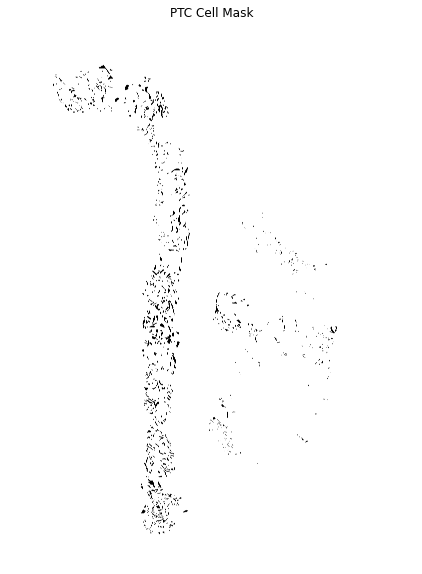

In [3]:
mask = tiff.imread('/orange/pinaki.sarder/durgasrit.dongla/PTC_IPTCR/Data/All_Masks/S15-69213CD34LCA.tiff')
plt.figure(figsize=(10, 10))
plt.imshow(mask, cmap='binary')  # binary colormap: black background, white annotations
plt.title('PTC Cell Mask')
plt.axis('off')
plt.show()

### Step 2: Training Data Generation
For each WSI and its corresponding mask:
- Identify individual PTC regions
- Generate multiple 512x512 patches around each PTC with random offsets:
  - Random x offset: -100 to +100 pixels
  - Random y offset: -100 to +100 pixels
- Save corresponding pairs of:
  - WSI patches showing the tissue
  - Mask patches showing the PTC annotations
- Storing them as .png images

Path to all the Training Data Images: /orange/pinaki.sarder/durgasrit.dongla/PTC_IPTCR/Data/Training_Data

Found 11 folders to process

Processing folder: S15-74400CD34LCA
Generating patches with 25.0% overlap (stride=168)
Expected patches to process: ~1925
Generated 207 valid patches out of 1925 total
Ignored 1718 patches (100% background)

Valid Patches (with foreground):


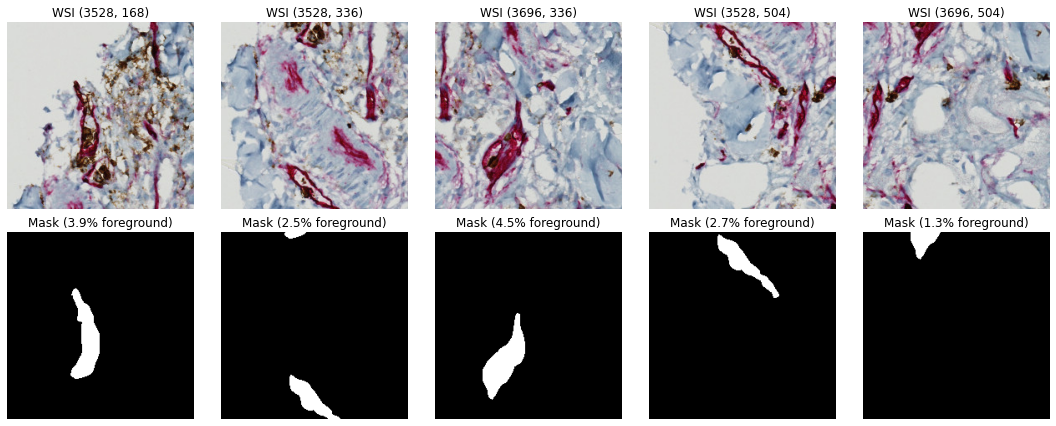


Ignored Patches (100% background):


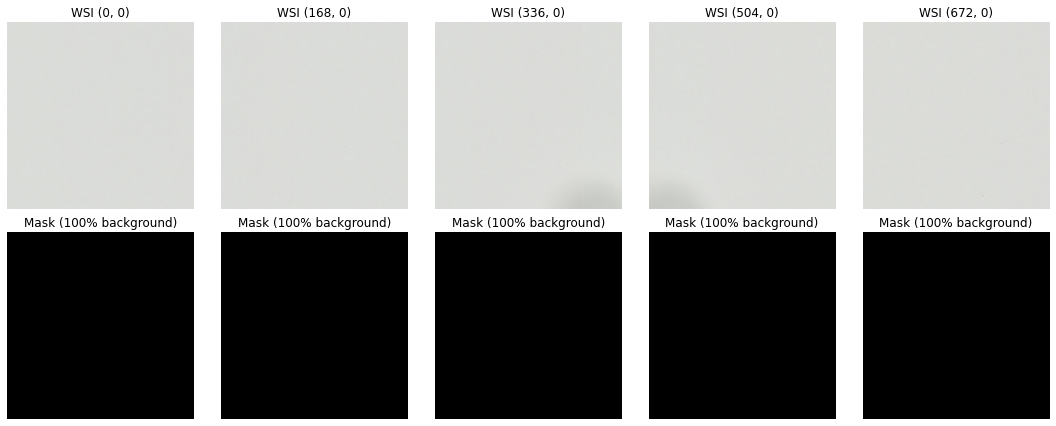


Processing folder: S15-77276CD34LCA
Generating patches with 25.0% overlap (stride=168)
Expected patches to process: ~3040
Generated 465 valid patches out of 3040 total
Ignored 2575 patches (100% background)

Valid Patches (with foreground):


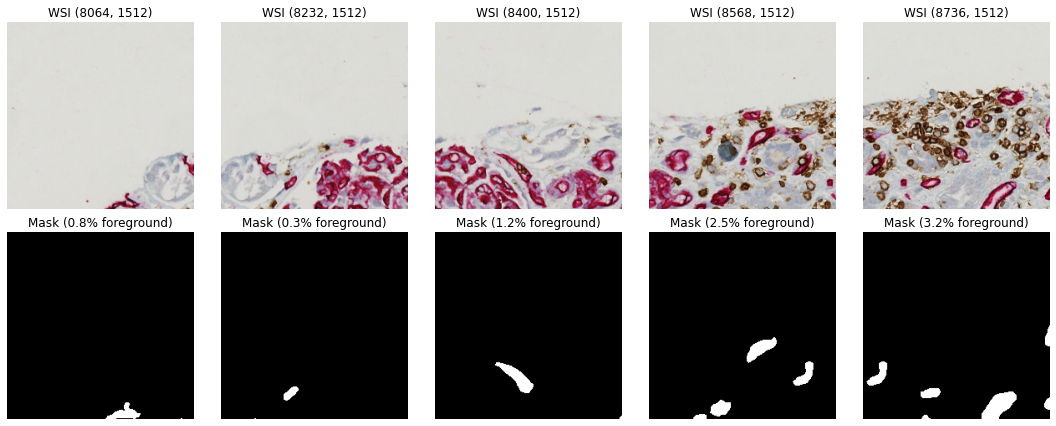


Ignored Patches (100% background):


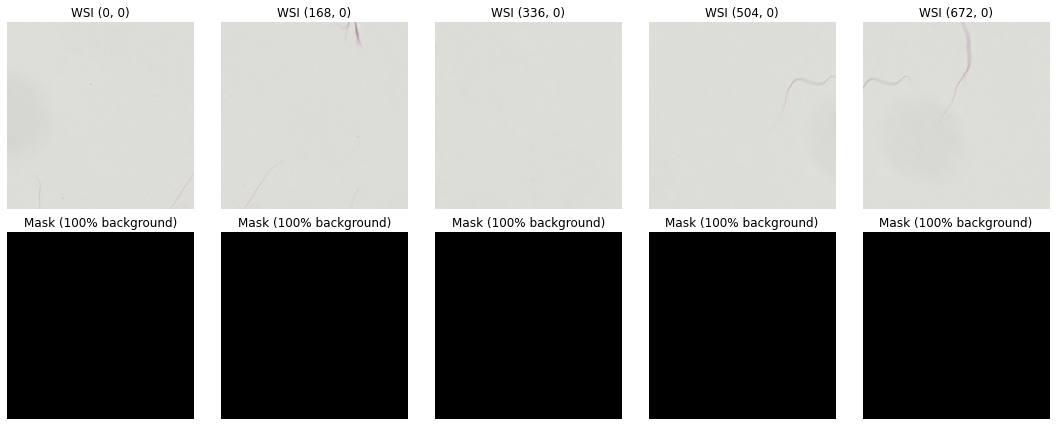


Processing folder: S08-43678CD34LCA
Generating patches with 25.0% overlap (stride=168)
Expected patches to process: ~4100
Generated 898 valid patches out of 4000 total
Ignored 3102 patches (100% background)

Valid Patches (with foreground):


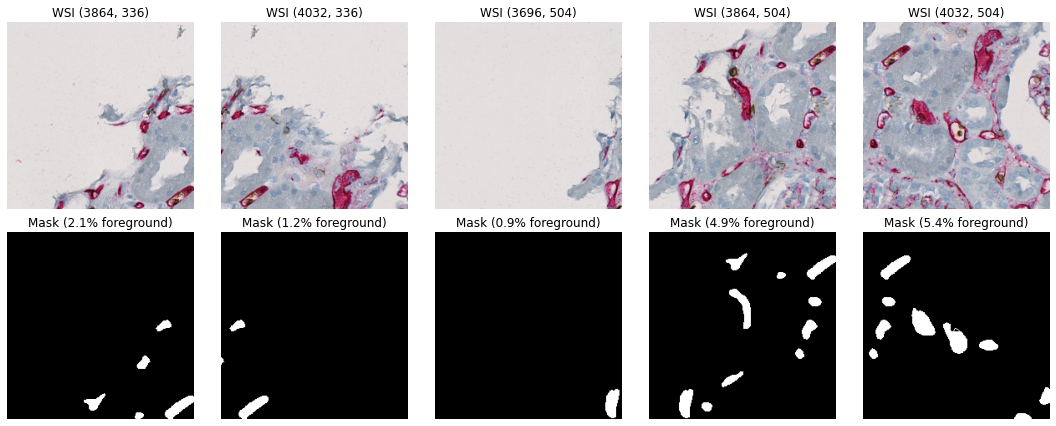


Ignored Patches (100% background):


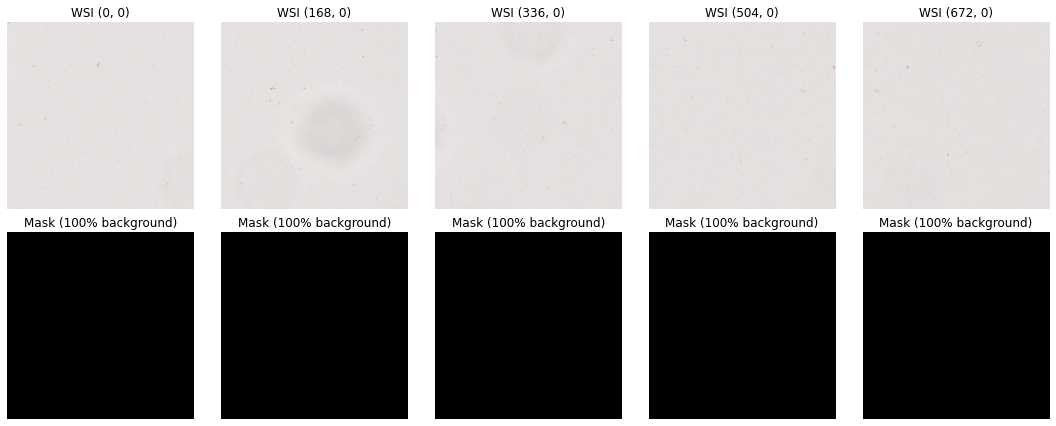


Processing folder: S15-68541CD34LCA
Generating patches with 25.0% overlap (stride=168)
Expected patches to process: ~2170
Generated 290 valid patches out of 2170 total
Ignored 1880 patches (100% background)

Valid Patches (with foreground):


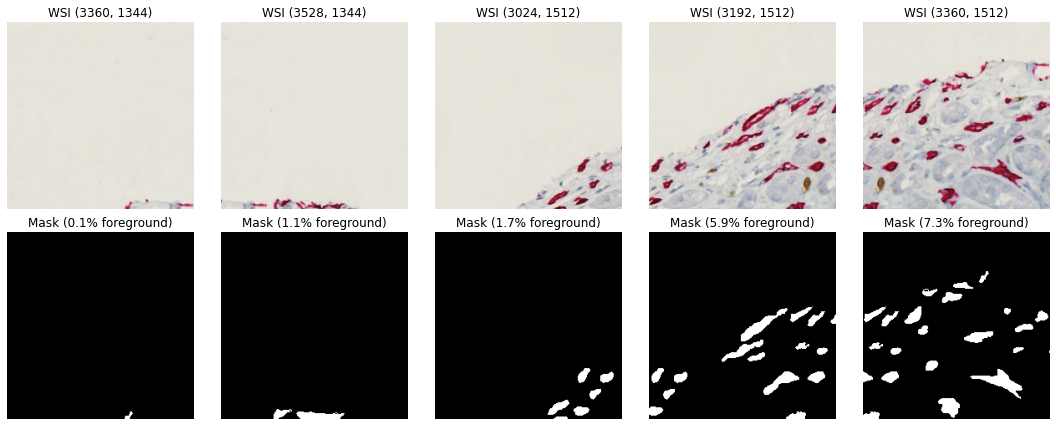


Ignored Patches (100% background):


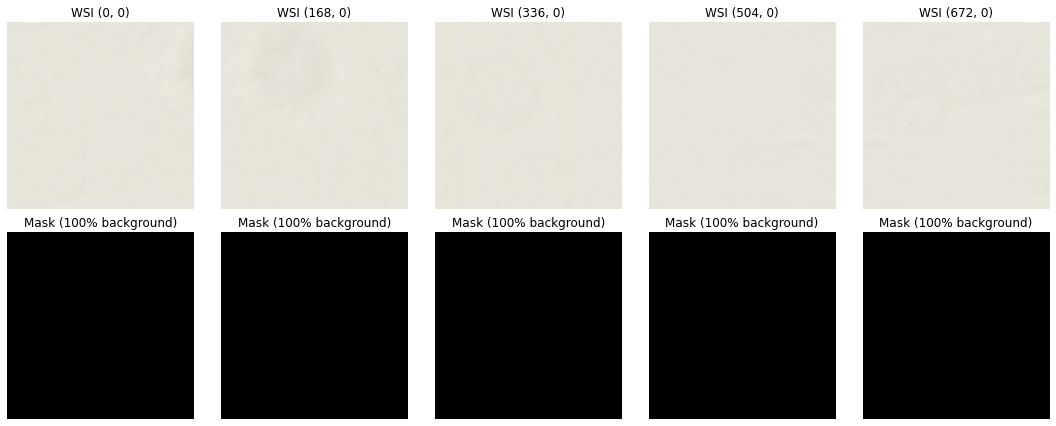


Processing folder: S06-23124CD34LCA
Generating patches with 25.0% overlap (stride=168)
Expected patches to process: ~4640
Generated 529 valid patches out of 4640 total
Ignored 4111 patches (100% background)

Valid Patches (with foreground):


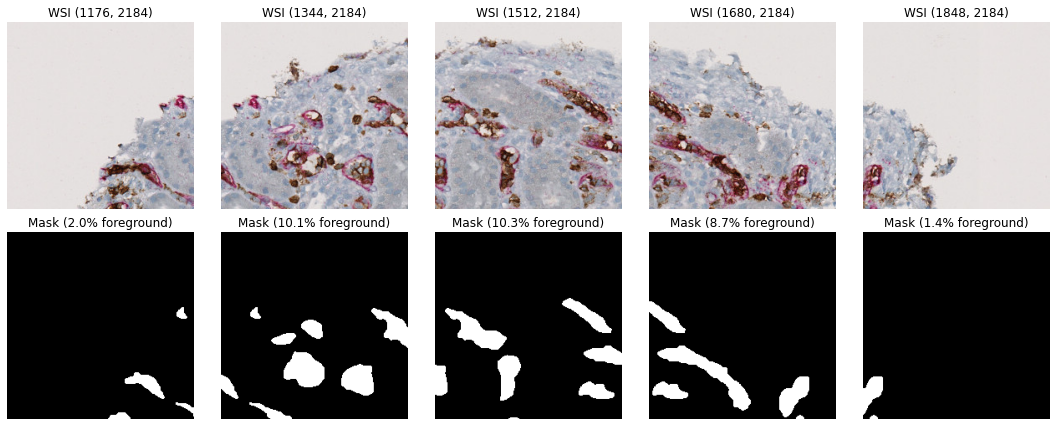


Ignored Patches (100% background):


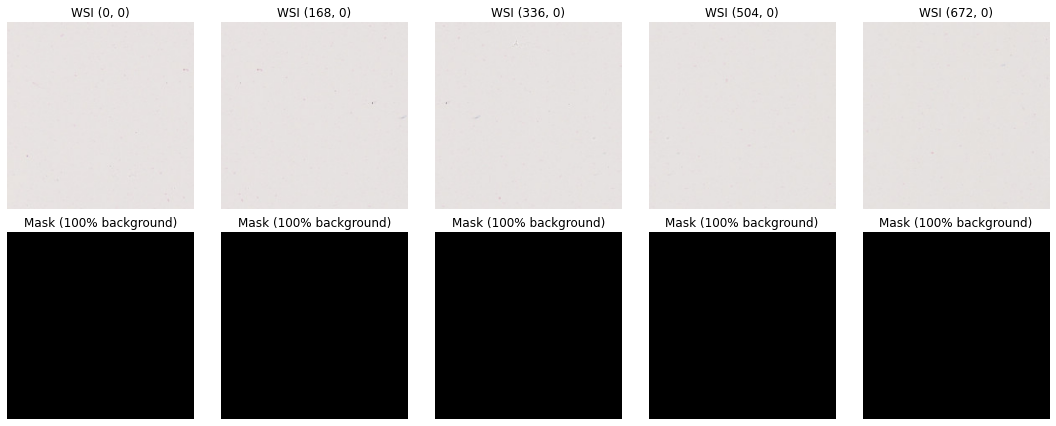


Processing folder: S15-69213CD34LCA
Generating patches with 25.0% overlap (stride=168)
Expected patches to process: ~2852
Generated 481 valid patches out of 2852 total
Ignored 2371 patches (100% background)

Valid Patches (with foreground):


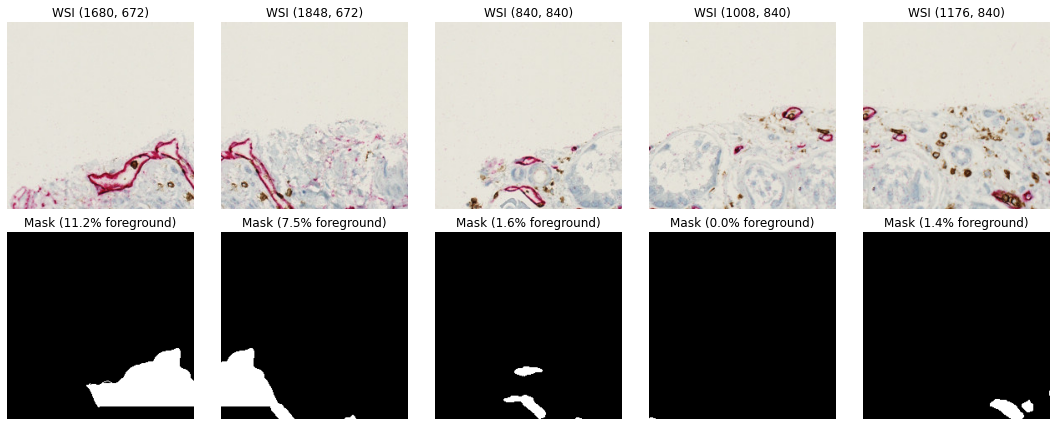


Ignored Patches (100% background):


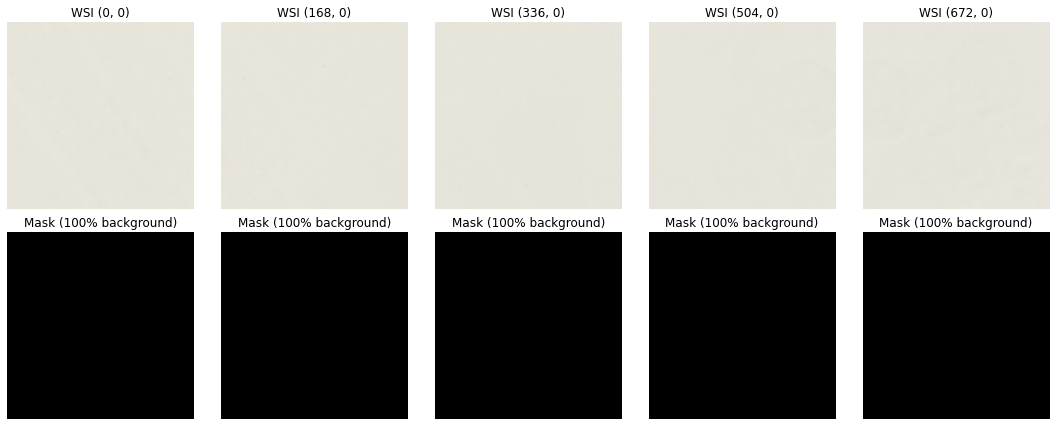


Processing folder: S09-63505CD34LCA
Generating patches with 25.0% overlap (stride=168)
Expected patches to process: ~2940
Generated 353 valid patches out of 2940 total
Ignored 2587 patches (100% background)

Valid Patches (with foreground):


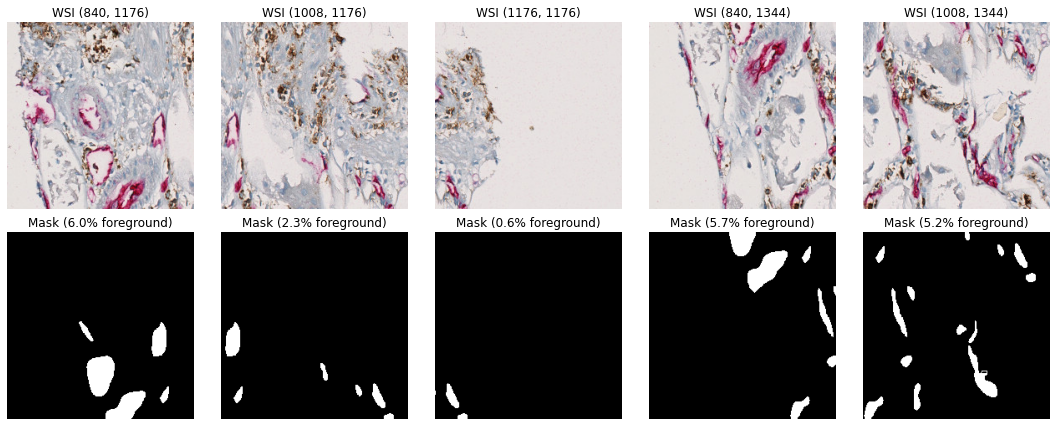


Ignored Patches (100% background):


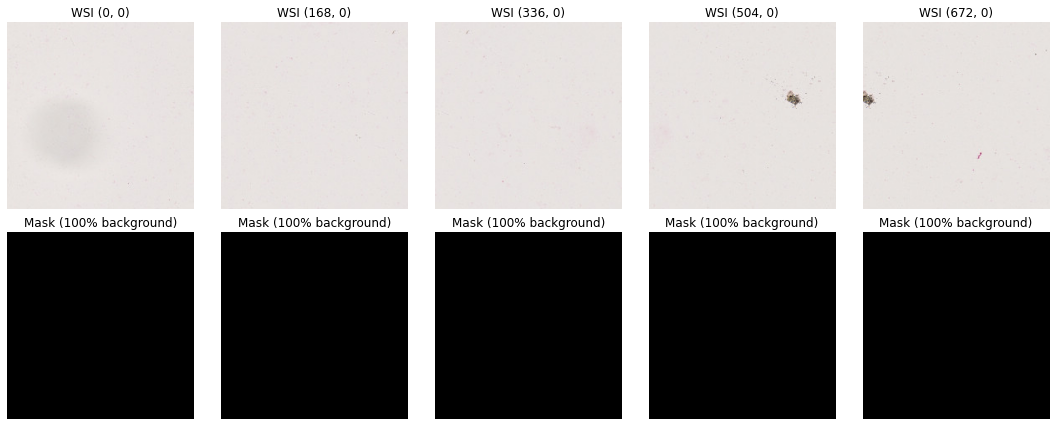


Processing folder: S15-69206CD34LCA
Generating patches with 25.0% overlap (stride=168)
Expected patches to process: ~3900
Generated 450 valid patches out of 3900 total
Ignored 3450 patches (100% background)

Valid Patches (with foreground):


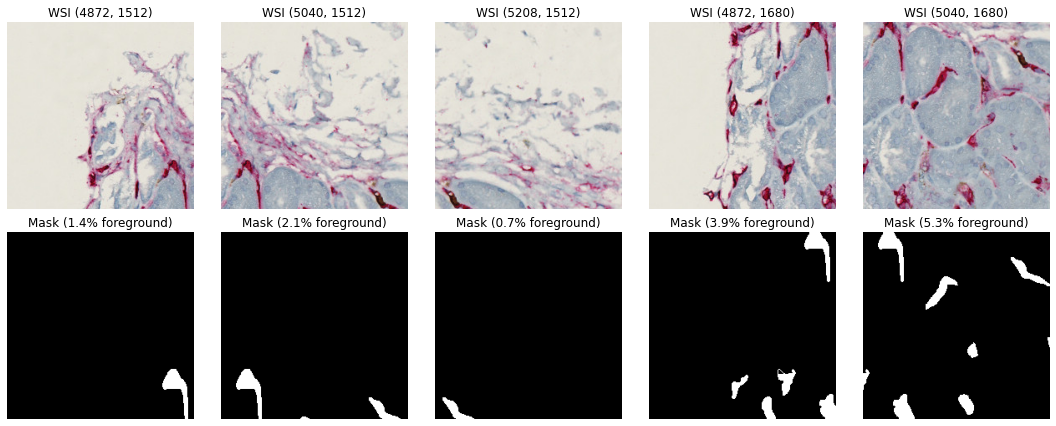


Ignored Patches (100% background):


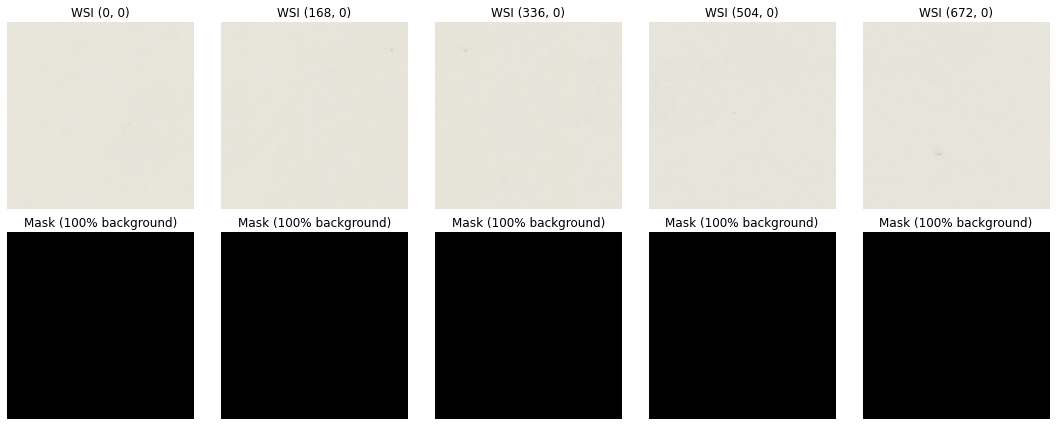


Processing folder: S15-77273 - 2016-12-12 16.55.44
Generating patches with 25.0% overlap (stride=168)
Expected patches to process: ~2378
Generated 278 valid patches out of 2320 total
Ignored 2042 patches (100% background)

Valid Patches (with foreground):


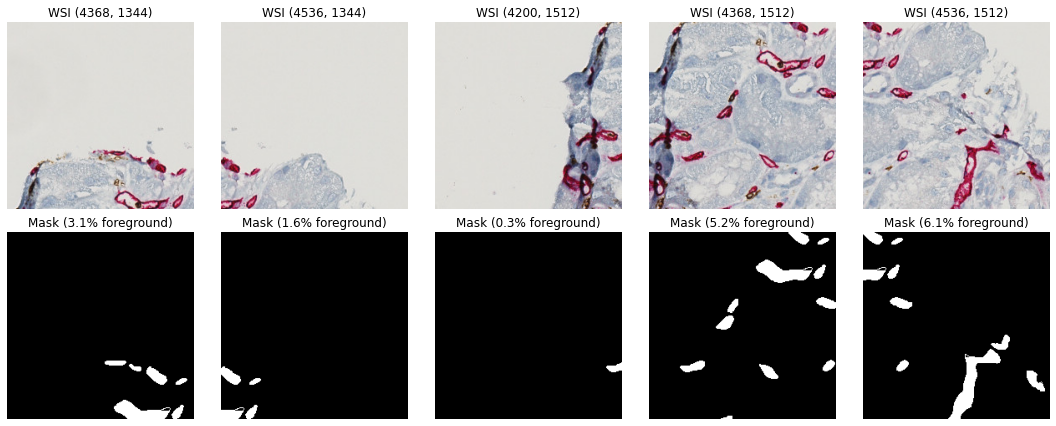


Ignored Patches (100% background):


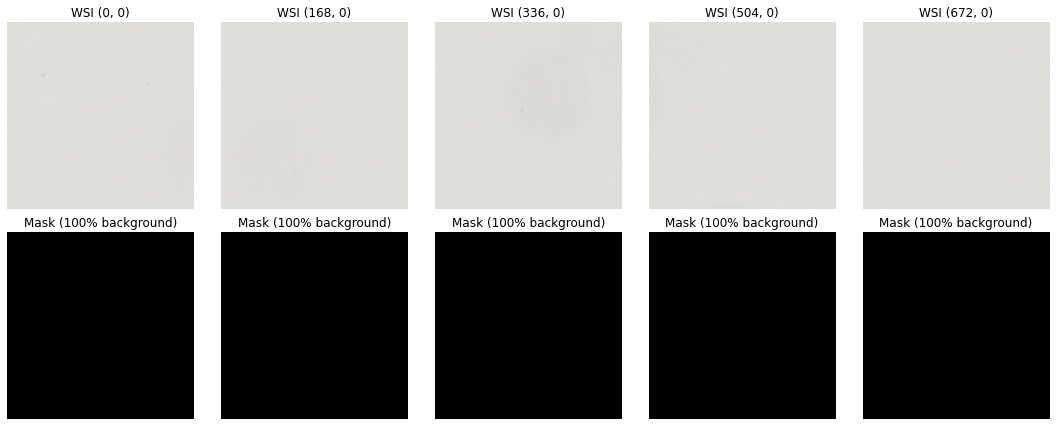


Processing folder: S15-68761CD34LCA
Generating patches with 25.0% overlap (stride=168)
Expected patches to process: ~4408
Generated 531 valid patches out of 4408 total
Ignored 3877 patches (100% background)

Valid Patches (with foreground):


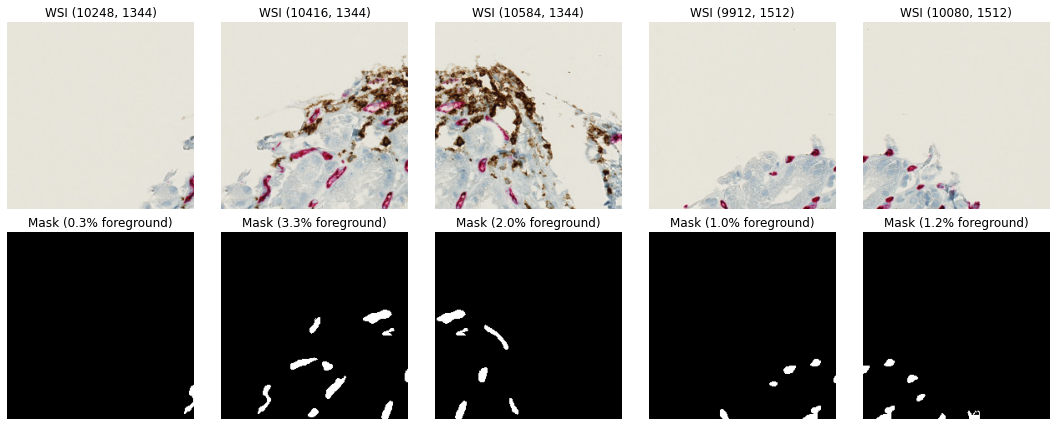


Ignored Patches (100% background):


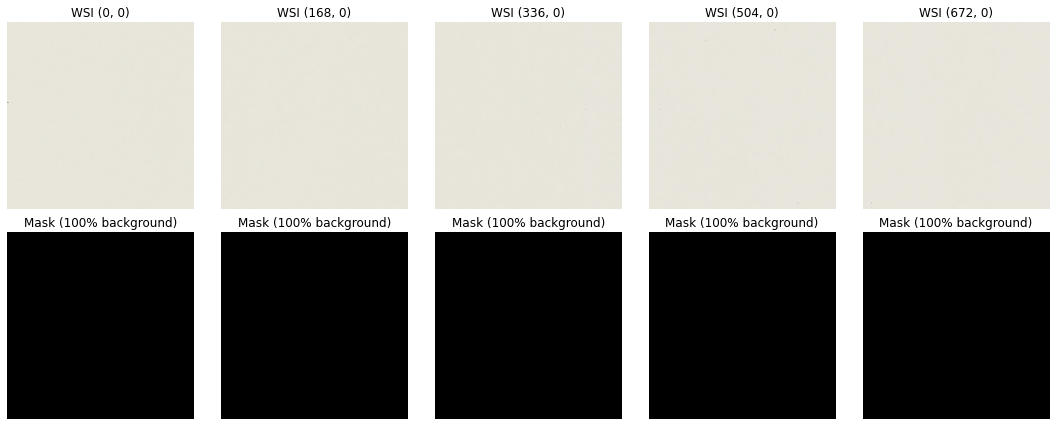


Processing folder: S15-46586CD34LCA
Generating patches with 25.0% overlap (stride=168)
Expected patches to process: ~1540
Generated 309 valid patches out of 1540 total
Ignored 1231 patches (100% background)

Valid Patches (with foreground):


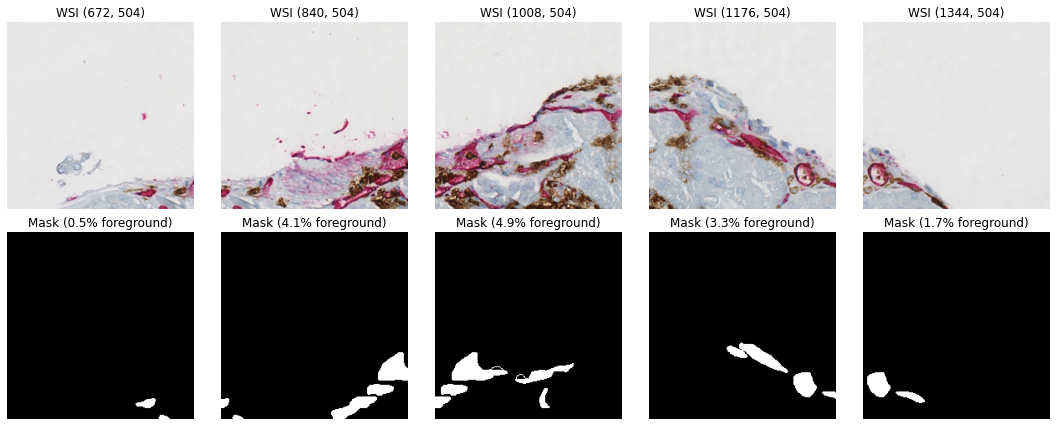


Ignored Patches (100% background):


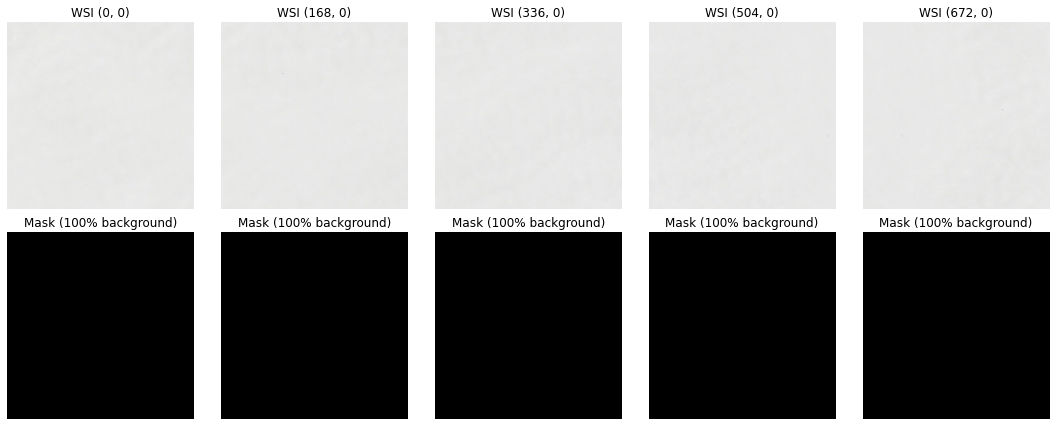

In [4]:
from openslide import OpenSlide
import cv2 as cv
import os
import numpy as np
from tifffile import imread
import matplotlib.pyplot as plt
import shutil
from IPython.display import display

def generate_and_visualize_patches(wsi_path, mask_path, output_dir, 
                                  patch_size=224, overlap=0.5, num_samples=5):
    """
    Generate patches using sliding window and visualize both valid and ignored patches.
    
    Args:
        wsi_path: Path to the whole slide image
        mask_path: Path to the mask image
        output_dir: Directory to save the valid patches for training
        patch_size: Size of the patches (square)
        overlap: Overlap between patches (0-1)
        num_samples: Number of sample patches to visualize
    """
    try:
        # Open WSI and load mask
        slide = OpenSlide(wsi_path)
        mask = imread(mask_path)
        level = 2 
        factor = slide.level_downsamples[level]
        
        # Get dimensions at the specified level
        width, height = slide.level_dimensions[level]
        
        # Create output directories
        image_dir = os.path.join(output_dir, 'image')
        mask_dir = os.path.join(output_dir, 'mask')
        os.makedirs(image_dir, exist_ok=True)
        os.makedirs(mask_dir, exist_ok=True)
        
        # Calculate stride based on overlap
        stride = int(patch_size * (1 - overlap))
        
        # Track counts
        total_patches = 0
        valid_patches = 0
        
        # Store sample patches for visualization
        valid_samples = []
        ignored_samples = []
        
        # Calculate total expected patches for progress tracking
        expected_patches = ((width - patch_size) // stride + 1) * ((height - patch_size) // stride + 1)
        
        print(f"Generating patches with {overlap*100:.1f}% overlap (stride={stride})")
        print(f"Expected patches to process: ~{expected_patches}")
        
        # Generate patches with sliding window
        for y in range(0, height - patch_size, stride):
            for x in range(0, width - patch_size, stride):
                total_patches += 1
                
                # Extract mask patch
                mask_patch = mask[y:y+patch_size, x:x+patch_size]
                
                # Extract WSI patch (convert to level 0 coordinates)
                patch_x0 = int(x * factor)
                patch_y0 = int(y * factor)
                wsi_patch = slide.read_region((patch_x0, patch_y0), level, (patch_size, patch_size))
                wsi_patch = cv.cvtColor(np.array(wsi_patch), cv.COLOR_RGBA2RGB)
                
                # Check if patch is 100% background
                foreground_pixels = np.sum(mask_patch > 0)
                
                if foreground_pixels == 0:  # 100% background - IGNORED
                    # Store for visualization if needed
                    if len(ignored_samples) < num_samples:
                        ignored_samples.append({
                            'patch': wsi_patch,
                            'mask': mask_patch,
                            'coords': (x, y)
                        })
                else:  # Has foreground - VALID
                    # Save patch for training
                    patch_id = f'patch_{x}_{y}'
                    
                    # Save as BGR for OpenCV
                    cv.imwrite(
                        os.path.join(image_dir, f'{patch_id}.png'),
                        cv.cvtColor(wsi_patch, cv.COLOR_RGB2BGR)
                    )
                    
                    # For masks, save as is (grayscale)
                    cv.imwrite(
                        os.path.join(mask_dir, f'{patch_id}.png'),
                        mask_patch
                    )
                    
                    # Store for visualization if needed
                    if len(valid_samples) < num_samples:
                        valid_samples.append({
                            'patch': wsi_patch,
                            'mask': mask_patch,
                            'coords': (x, y),
                            'id': patch_id
                        })
                    
                    valid_patches += 1
        
        print(f"Generated {valid_patches} valid patches out of {total_patches} total")
        print(f"Ignored {total_patches - valid_patches} patches (100% background)")
        
        # Display valid patches directly in the notebook
        if valid_samples:
            print("\nValid Patches (with foreground):")
            fig, axes = plt.subplots(2, min(num_samples, len(valid_samples)), figsize=(15, 6))
            if len(valid_samples) == 1:
                axes = np.array([[axes[0]], [axes[1]]])
                
            for i, patch_data in enumerate(valid_samples):
                if i >= num_samples:
                    break
                    
                # Display WSI patch
                axes[0, i].imshow(patch_data['patch'])
                axes[0, i].set_title(f"WSI ({patch_data['coords'][0]}, {patch_data['coords'][1]})")
                axes[0, i].axis('off')
                
                # Display mask patch
                axes[1, i].imshow(patch_data['mask'], cmap='gray')
                fg_percent = (np.sum(patch_data['mask'] > 0) / (patch_size * patch_size) * 100)
                axes[1, i].set_title(f"Mask ({fg_percent:.1f}% foreground)")
                axes[1, i].axis('off')
            
            plt.tight_layout()
            display(fig)
            plt.close()
        
        # Display ignored patches directly in the notebook
        if ignored_samples:
            print("\nIgnored Patches (100% background):")
            fig, axes = plt.subplots(2, min(num_samples, len(ignored_samples)), figsize=(15, 6))
            if len(ignored_samples) == 1:
                axes = np.array([[axes[0]], [axes[1]]])
                
            for i, patch_data in enumerate(ignored_samples):
                if i >= num_samples:
                    break
                    
                # Display WSI patch
                axes[0, i].imshow(patch_data['patch'])
                axes[0, i].set_title(f"WSI ({patch_data['coords'][0]}, {patch_data['coords'][1]})")
                axes[0, i].axis('off')
                
                # Display mask patch
                axes[1, i].imshow(patch_data['mask'], cmap='gray')
                axes[1, i].set_title(f"Mask (100% background)")
                axes[1, i].axis('off')
            
            plt.tight_layout()
            display(fig)
            plt.close()
        
        return valid_patches, total_patches - valid_patches
        
    except Exception as e:
        print(f"Error processing {wsi_path}: {e}")
        return 0, 0

def process_all_images(base_path, masks_path, overlap=0.5, num_samples=5):
    """Process all images using sliding window approach and visualize results"""
    # Create directories
    training_dir = "/orange/pinaki.sarder/durgasrit.dongla/PTC_IPTCR/Data/Training_Data_Zoom2"
    if os.path.exists(training_dir):
        shutil.rmtree(training_dir)
        
    os.makedirs(training_dir, exist_ok=True)
    
    # Get all folders
    folders = [f for f in os.listdir(base_path) 
              if os.path.isdir(os.path.join(base_path, f)) and f != "All_Masks"]
    
    print(f"Found {len(folders)} folders to process")
    
    for folder in folders:
        print(f"\n{'='*50}")
        print(f"Processing folder: {folder}")
        print(f"{'='*50}")
        
        try:
            # Set up paths
            folder_path = os.path.join(base_path, folder)
            ndpi_files = [f for f in os.listdir(folder_path) if f.endswith('.ndpi')]
            
            if not ndpi_files:
                print(f"No .ndpi file found in {folder}")
                continue
                
            ndpi_file = ndpi_files[0]
            wsi_path = os.path.join(folder_path, ndpi_file)
            mask_path = os.path.join(masks_path, f"{folder}.tiff")
            
            if not os.path.exists(mask_path):
                print(f"Mask not found for {folder}: {mask_path}")
                continue
            
            # Create output directory
            output_dir = os.path.join(training_dir, folder)
            os.makedirs(output_dir, exist_ok=True)
            
            # Generate patches and visualize
            generate_and_visualize_patches(
                wsi_path, mask_path, output_dir, 
                overlap=overlap, num_samples=num_samples
            )
            
        except Exception as e:
            print(f"Error with folder {folder}: {e}")

# Example usage 
base_path = "/orange/pinaki.sarder/durgasrit.dongla/PTC_IPTCR/Data/Raw_Data" 
masks_path = "/orange/pinaki.sarder/durgasrit.dongla/PTC_IPTCR/Data/All_Masks"
process_all_images(base_path, masks_path, overlap=0.25, num_samples=5)

### Step 3: Creating the tf Dataset

Split the data into training, validation, and test sets:
- Assign:
  - First 8 folders to the training set
  - Next 2 folders to the validation set
  - Last folder to the test set
- Combine image and mask paths within each split
- Return structured splits for downstream usage

Then, we create TFRecord files from the image-mask pairs:
- For each split (train, val, test):
  - Serialize valid samples into TFRecord format using:
  - image: RGB image converted to bytes
  - mask: grayscale mask converted to bytes
- Save each split’s TFRecord to disk


In [5]:
import os  # Import first to avoid TF auto-initialization

# Set TensorFlow to avoid pre-initializing GPUs
os.environ["TF_FORCE_GPU_ALLOW_GROWTH"] = "true"

import tensorflow as tf

# GPU Setup (Must be before any TF operation)
physical_devices = tf.config.list_physical_devices('GPU')
if physical_devices:
    for device in physical_devices:
        tf.config.experimental.set_memory_growth(device, True)

# Import Keras mixed precision after GPU setup
from tensorflow.keras import mixed_precision

# Enable mixed precision
tf.keras.mixed_precision.set_global_policy('mixed_float16')

print("GPU memory growth set successfully!")


2025-04-03 08:20:46.602845: I tensorflow/stream_executor/platform/default/dso_loader.cc:49] Successfully opened dynamic library libcudart.so.11.0


INFO:tensorflow:Mixed precision compatibility check (mixed_float16): OK
Your GPU will likely run quickly with dtype policy mixed_float16 as it has compute capability of at least 7.0. Your GPU: NVIDIA GeForce RTX 2080 Ti, compute capability 7.5
GPU memory growth set successfully!


2025-04-03 08:20:53.810535: I tensorflow/compiler/jit/xla_cpu_device.cc:41] Not creating XLA devices, tf_xla_enable_xla_devices not set
2025-04-03 08:20:53.815169: I tensorflow/stream_executor/platform/default/dso_loader.cc:49] Successfully opened dynamic library libcuda.so.1
2025-04-03 08:20:53.867685: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1720] Found device 0 with properties: 
pciBusID: 0000:60:00.0 name: NVIDIA GeForce RTX 2080 Ti computeCapability: 7.5
coreClock: 1.545GHz coreCount: 68 deviceMemorySize: 10.75GiB deviceMemoryBandwidth: 573.69GiB/s
2025-04-03 08:20:53.867725: I tensorflow/stream_executor/platform/default/dso_loader.cc:49] Successfully opened dynamic library libcudart.so.11.0
2025-04-03 08:20:53.886808: I tensorflow/stream_executor/platform/default/dso_loader.cc:49] Successfully opened dynamic library libcublas.so.11
2025-04-03 08:20:53.886889: I tensorflow/stream_executor/platform/default/dso_loader.cc:49] Successfully opened dynamic library libcublasLt.

In [6]:
import tensorflow as tf
import cv2
import os
import numpy as np
from glob import glob
from pathlib import Path
import io
import pickle
import time

def _bytes_feature(value):
    return tf.train.Feature(bytes_list=tf.train.BytesList(value=[value]))

def calculate_background_percentage(mask):
    """Calculate the percentage of black pixels (background) in the mask."""
    total_pixels = mask.size
    # Count pixels that are black (0)
    background_pixels = np.sum(mask == 0)
    return (background_pixels / total_pixels) * 100

def create_tfrecord(image_paths, mask_paths, output_path):
    skipped_count = 0
    included_count = 0
    
    with tf.io.TFRecordWriter(output_path) as writer:
        for img_path, mask_path in zip(image_paths, mask_paths):
            # Read mask first to check background percentage
            mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
            
            # Calculate background percentage
            bg_percentage = calculate_background_percentage(mask)
            
            # Skip if mask is 100% background (all black)
            if bg_percentage == 100:
                skipped_count += 1
                continue
                
            # Only read and process image if mask has some non-background pixels
            image = cv2.imread(img_path)
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            
            # Convert to bytes
            image_bytes = tf.io.serialize_tensor(image)
            mask_bytes = tf.io.serialize_tensor(mask)
            
            # Create feature
            feature = {
                'image': _bytes_feature(image_bytes.numpy()),
                'mask': _bytes_feature(mask_bytes.numpy())
            }
            
            # Write example
            example = tf.train.Example(features=tf.train.Features(feature=feature))
            writer.write(example.SerializeToString())
            included_count += 1
    
    print(f"Created {output_path}:")
    print(f"Included images: {included_count}")
    print(f"Skipped images (100% black background): {skipped_count}")
    return included_count, skipped_count

def parse_tfrecord(example_proto):
    feature_description = {
        'image': tf.io.FixedLenFeature([], tf.string),
        'mask': tf.io.FixedLenFeature([], tf.string)
    }
    features = tf.io.parse_single_example(example_proto, feature_description)
    
    image = tf.io.parse_tensor(features['image'], out_type=tf.uint8)
    mask = tf.io.parse_tensor(features['mask'], out_type=tf.uint8)
    
    image = tf.cast(image, tf.float32) / 255.0
    mask = tf.cast(mask, tf.float32) / 255.0
    mask = tf.expand_dims(mask, axis=-1)
    
    image.set_shape([224, 224, 3])
    mask.set_shape([224, 224, 1])
    
    return image, mask

def create_dataset(tfrecord_path, batch_size=16):
    dataset = tf.data.TFRecordDataset(tfrecord_path)
    dataset = dataset.map(parse_tfrecord, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.shuffle(1000)
    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

def collect_images_from_folders(base_path):
    """Collect images from multiple folders and organize them by folder."""
    folder_paths = sorted(glob(os.path.join(base_path, "*")))
    all_folder_data = []
    
    for folder_path in folder_paths:
        if os.path.isdir(folder_path):
            images = sorted(glob(os.path.join(folder_path, "image", "*.png")))
            masks = sorted(glob(os.path.join(folder_path, "mask", "*.png")))
            
            if len(images) > 0 and len(masks) > 0:
                all_folder_data.append({
                    'folder': os.path.basename(folder_path),
                    'images': images,
                    'masks': masks
                })
    
    return all_folder_data

def split_folders(all_folder_data):
    """Split folders into train, validation, and test sets."""
    # Using first 8 folders for training
    train_folders = all_folder_data[:8]
    
    # Next 2 folders for validation
    val_folders = all_folder_data[8:10]
    
    # Last folder for test
    test_folders = all_folder_data[10:]
    
    # Combine images and masks for each split
    def combine_folder_data(folders):
        all_images = []
        all_masks = []
        for folder in folders:
            all_images.extend(folder['images'])
            all_masks.extend(folder['masks'])
        return all_images, all_masks
    
    train_images, train_masks = combine_folder_data(train_folders)
    val_images, val_masks = combine_folder_data(val_folders)
    test_images, test_masks = combine_folder_data(test_folders)
    
    return {
        'train': (train_images, train_masks),
        'val': (val_images, val_masks),
        'test': (test_images, test_masks)
    }

# Create TFRecords
processed_data_path = "/orange/pinaki.sarder/durgasrit.dongla/PTC_IPTCR/Data/Training_Data_Zoom2"
tfrecord_dir = "/orange/pinaki.sarder/durgasrit.dongla/PTC_IPTCR/Data/TFRecords_Zoom2"
os.makedirs(tfrecord_dir, exist_ok=True)

# Collect and split data
all_folder_data = collect_images_from_folders(processed_data_path)
split_data = split_folders(all_folder_data)

# Print folder distribution
print("\nFolder Distribution:")
print(f"Training folders: {[f['folder'] for f in all_folder_data[:8]]}")
print(f"Validation folders: {[f['folder'] for f in all_folder_data[8:10]]}")
print(f"Test folders: {[f['folder'] for f in all_folder_data[10:]]}")

# Dictionary to store statistics
stats = {}

# Create TFRecords for each split
for split_name, (images, masks) in split_data.items():
    tfrecord_path = os.path.join(tfrecord_dir, f"{split_name}.tfrecord")
    included, skipped = create_tfrecord(images, masks, tfrecord_path)
    
    stats[split_name] = {
        'total': len(images),
        'included': included,
        'skipped': skipped
    }

# Print overall statistics
print("\nOverall Statistics:")
for split_name, values in stats.items():
    print(f"\n{split_name.upper()} split:")
    print(f"Total images: {values['total']}")
    print(f"Included images: {values['included']} ({values['included']/values['total']*100:.1f}%)")
    print(f"Skipped images: {values['skipped']} ({values['skipped']/values['total']*100:.1f}%)")

# Create datasets
train_dataset = create_dataset(os.path.join(tfrecord_dir, "train.tfrecord"), batch_size=16)
valid_dataset = create_dataset(os.path.join(tfrecord_dir, "val.tfrecord"), batch_size=16)
test_dataset = create_dataset(os.path.join(tfrecord_dir, "test.tfrecord"), batch_size=16)


Folder Distribution:
Training folders: ['S06-23124CD34LCA', 'S08-43678CD34LCA', 'S09-63505CD34LCA', 'S15-46586CD34LCA', 'S15-68541CD34LCA', 'S15-68761CD34LCA', 'S15-69206CD34LCA', 'S15-69213CD34LCA']
Validation folders: ['S15-74400CD34LCA', 'S15-77273 - 2016-12-12 16.55.44']
Test folders: ['S15-77276CD34LCA']


2025-04-03 08:21:07.847849: I tensorflow/core/platform/cpu_feature_guard.cc:142] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-04-03 08:21:07.848337: I tensorflow/compiler/jit/xla_gpu_device.cc:99] Not creating XLA devices, tf_xla_enable_xla_devices not set
2025-04-03 08:21:07.848932: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1720] Found device 0 with properties: 
pciBusID: 0000:60:00.0 name: NVIDIA GeForce RTX 2080 Ti computeCapability: 7.5
coreClock: 1.545GHz coreCount: 68 deviceMemorySize: 10.75GiB deviceMemoryBandwidth: 573.69GiB/s
2025-04-03 08:21:07.848974: I tensorflow/stream_executor/platform/default/dso_loader.cc:49] Successfully opened dynamic library libcudart.so.11.0
2025-04-03 08:21:07.848998: I tensorflow/stream_executor/platform/default/d

Created /orange/pinaki.sarder/durgasrit.dongla/PTC_IPTCR/Data/TFRecords_Zoom2/train.tfrecord:
Included images: 3841
Skipped images (100% black background): 0
Created /orange/pinaki.sarder/durgasrit.dongla/PTC_IPTCR/Data/TFRecords_Zoom2/val.tfrecord:
Included images: 485
Skipped images (100% black background): 0
Created /orange/pinaki.sarder/durgasrit.dongla/PTC_IPTCR/Data/TFRecords_Zoom2/test.tfrecord:
Included images: 465
Skipped images (100% black background): 0

Overall Statistics:

TRAIN split:
Total images: 3841
Included images: 3841 (100.0%)
Skipped images: 0 (0.0%)

VAL split:
Total images: 485
Included images: 485 (100.0%)
Skipped images: 0 (0.0%)

TEST split:
Total images: 465
Included images: 465 (100.0%)
Skipped images: 0 (0.0%)
